# Group Project ST3005 source code

Any sort of comments can be added here, either to explain the question answered or explain what we are doing or anything else that you might find interesting.

---

Import of necessary libraries

In [50]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from scipy.spatial.distance import jaccard, hamming, mahalanobis, pdist, squareform
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score, cross_validate
import pandas as pd
import csv

np.random.seed(42)

# Set style 
plt.style.use('seaborn-v0_8-darkgrid')

Helper function to import the data from a .arff format

In [51]:
""" 
Imports data from an arff file and returns an array with all of it.
"""
def import_data(filename):
    with open(filename, "r") as file:
        brute_data = file.readlines()

    # First 175 lines are useless for actual processing ,
    # find where the metadata / data split is loctaed 
    split_idx = brute_data.index("@data\n")+1

    metadata = brute_data[:split_idx]
    raw_data = brute_data[split_idx:-3:]

    attributes = [l.split()[1].strip("'") for l in metadata 
                  if l.lower().startswith("@attribute")]

    data = list(csv.reader(raw_data, quotechar="'", skipinitialspace=True))
    return attributes, np.array(data, dtype=str)     

--- 

## kNN simple classification

First jump into the dataset, one to visualise it and second to lay down a sceleton that we can use after

In [ ]:
# Get the data and the labels for the different features
attributes, data = import_data("../data/dataset_24_mushroom.arff")

# The last column is the target
feature_names = attributes[:-1]
target_name = attributes[-1]

X = data[:, :-1]  # mushroom features
y = data[:, -1]   # target: edible or poisonous

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", feature_names)
print("Target:", target_name)

X shape: (8124, 22)
y shape: (8124,)
Features: ['cap-shape', 'cap-surface', 'cap-color', 'bruises%3F', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']
Target: class


Note: our data is not simply numbers as it was the case in the practicals we had, issue is knn needs to have numerical vaules to compute the distances, this can be achieved by using data frames like and the get_dummies function like such:
(get_dummies is usefull since for each instance it creates a column for each possibility, example, we have 'odor' and its possible cases { 'a', 'c', 'f', 'l', 'm', 'n', 'p', 's', 'y'}, and one entry has odor = n, get_dummies will create those columns for this specific entry : odor_a = 0, odor_c = 0 ... odor_n = 1, odor...., it allows to use knn in a non biased way) 

In [60]:
# Convert the NumPy array into a DataFrame
df = pd.DataFrame(data, columns=attributes)

# Separate features and target
X = pd.get_dummies(df.drop(columns="class"), dtype=int)
#print(X)
y = df["class"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)


Accuracy: 1.0
Training accuracy: 1.0
Test accuracy: 1.0
Features: ['cap-shape_b', 'cap-shape_c', 'cap-shape_f', 'cap-shape_k', 'cap-shape_s', 'cap-shape_x', 'cap-surface_f', 'cap-surface_g', 'cap-surface_s', 'cap-surface_y', 'cap-color_b', 'cap-color_c', 'cap-color_e', 'cap-color_g', 'cap-color_n', 'cap-color_p', 'cap-color_r', 'cap-color_u', 'cap-color_w', 'cap-color_y', 'bruises%3F_f', 'bruises%3F_t', 'odor_a', 'odor_c', 'odor_f', 'odor_l', 'odor_m', 'odor_n', 'odor_p', 'odor_s', 'odor_y', 'gill-attachment_a', 'gill-attachment_f', 'gill-spacing_c', 'gill-spacing_w', 'gill-size_b', 'gill-size_n', 'gill-color_b', 'gill-color_e', 'gill-color_g', 'gill-color_h', 'gill-color_k', 'gill-color_n', 'gill-color_o', 'gill-color_p', 'gill-color_r', 'gill-color_u', 'gill-color_w', 'gill-color_y', 'stalk-shape_e', 'stalk-shape_t', 'stalk-root_?', 'stalk-root_b', 'stalk-root_c', 'stalk-root_e', 'stalk-root_r', 'stalk-surface-above-ring_f', 'stalk-surface-above-ring_k', 'stalk-surface-above-ring_s',

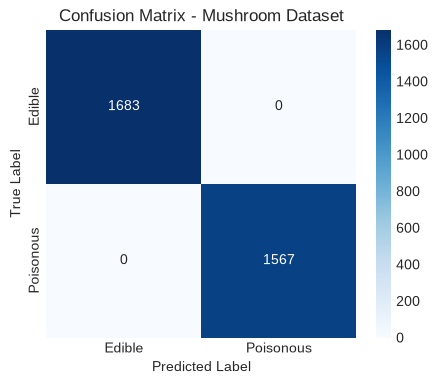

In [61]:
# Train kNN
knn = KNeighborsClassifier(n_neighbors=5, metric="hamming")
knn.fit(X_train, y_train)

print("Accuracy:", knn.score(X_test, y_test))
print("Training accuracy:", knn.score(X_train, y_train))
print("Test accuracy:", knn.score(X_test, y_test))

print("Features:", X.columns.tolist())
print("Target:", y.name)

# Predict 
y_pred = knn.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=["e", "p"])

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Edible", "Poisonous"],
    yticklabels=["Edible", "Poisonous"]
)

plt.title("Confusion Matrix - Mushroom Dataset")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.show()

In [ ]:
scores = cross_val_score(
    KNeighborsClassifier(n_neighbors=5, metric="hamming"),
    X,
    y,
    cv=5
)

print("Fold accuracies:", scores)
print("Mean accuracy:", scores.mean())

# had to double check since the prediction is perfect, we probably have a too good dataset or I made an oopise somewhere


Fold accuracies: [0.85107692 1.         0.99507692 1.         0.72044335]
Mean accuracy: 0.9133194391815082
